In [13]:
%pip install torch
%pip install transformers


Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


### define chat class to load data

In [13]:
from torch.utils.data import Dataset
import json

class ChatData(Dataset):
    def __init__(self, path:str, tokenizer):
        self.data = json.load(open(path, "r"))

        self.X = []
        for i in self.data:
            for j in i['dialog']:
                self.X.append(j['text'])
        
        
        # ... existing code ...
        with open("./data/chat_data.txt", "w", encoding='utf-8') as file_format:
            for idx, i in enumerate(self.X):
                try:
                    self.X[idx] = "<startofstring> "+i+" <bot>: "+self.X[idx+1]+" <endofstring>"
                    # file_format.write(self.X[idx]+"\n")
                except:
                    break    


        print("Number of conversations in X:", len(self.X))
        
        self.X = self.X[:10]
        print("training  data Number of conversations in X:", len(self.X))
        print("\nfirst data set:")
        print(self.X[0])

        print("\nsecond data set:")
        print(self.X[1])

        print("\n\n")
        self.X_encoded = tokenizer(self.X,max_length=100, truncation=True, padding="max_length", return_tensors="pt")
        self.input_ids = self.X_encoded['input_ids']
        self.attention_mask = self.X_encoded['attention_mask']

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return (self.input_ids[idx], self.attention_mask[idx])

In [5]:
from transformers import GPT2LMHeadModel, GPT2Tokenizer
from torch.optim import Adam
from torch.utils.data import DataLoader
import tqdm
import torch
import numpy as np

### initial tokenizer

In [8]:
device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"

print(f"using device : {device}")

# tokenizer
tokenizer = GPT2Tokenizer.from_pretrained("gpt2")

# add special tokens
tokenizer.add_special_tokens({"pad_token": "<pad>", 
                                "bos_token": "<startofstring>",
                                "eos_token": "<endofstring>"})
# add bot token
tokenizer.add_tokens(["<bot>:"])

using device : cpu


1

### load gpt2 model

In [9]:
# load model
model = GPT2LMHeadModel.from_pretrained("gpt2")

print("token_len: ", len(tokenizer))    
# resize token embeddings   
model.resize_token_embeddings(len(tokenizer))

# move model to device (cpu or gpu)
model = model.to(device)


token_len:  50261


### test gpt-2 model

In [10]:
print("test infer from gpt-2 : ")
input_tokens = tokenizer("how are you ", return_tensors="pt").to(device)
print(tokenizer.decode(model.generate(**input_tokens)[0]))

Setting `pad_token_id` to `eos_token_id`:50256 for open-end generation.


test infer from gpt-2 : 


/home/ying/.local/lib/python3.8/site-packages/transformers/generation/utils.py:1259: UserWarning: Using the model-agnostic default `max_length` (=20) to control the generation length. We recommend setting `max_new_tokens` to control the maximum length of the generation.
  warnings.warn(


how are you <pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad>


### load dataset

In [11]:
# dataset
chatData = ChatData("./data/chat_data.json", tokenizer)

# dataLoader, batch_size 为 64
dataLoader =  DataLoader(chatData, batch_size=64)

I love iphone! i just bought new iphone!
Thats good for you, i'm not very into new tech
I am a college student and i am a college student
I am go to gym and live on donations
I am a vegan and i am in the midwest
So vegan... i have dogs maybe i should told then that they may eat cheap salads insted of meat
I would not mind having them in the office that would be hard for me
Dogs or vegan in office?
I am a vegetarian so i am vegan
Strange answer
I guess i just do not know what to ps4 experience with.
Hello
/test
Hey
What do you do?
I love painting, i love to paint
Hi
That sounds nice. i love green.
Неllo
Hello
Hello, how are you?
what is your name ?
hello
anybody there
On The Ball, City, the oldest football song in the world.
What’s up?
Thank you how are you
Text is not given. Please try to type /end and /test to reset the state and get text.
/test
Text is not given. Please try to type /end and /test to reset the state and get text.
/Test
Text is not given. Please try to type /end and /t

### define generate answer function

In [20]:
def infer(inp, model):
    inp = "<startofstring> "+inp+" <bot>: "
    inp = tokenizer(inp, return_tensors="pt").to(device)
    
    # Add debugging prints
    print(f"Input device: {inp.input_ids.device}")
    print(f"Model device: {next(model.parameters()).device}")
    
    output = model.generate(
        **inp,
        min_length=20,
        max_length=100,
        pad_token_id=tokenizer.pad_token_id,
        eos_token_id=tokenizer.eos_token_id,
        do_sample=True,
        temperature=0.9,
        top_p=0.9,
        top_k=50,
        no_repeat_ngram_size=2,
        num_return_sequences=1,
        early_stopping=True
    )
    
    # Add debugging print
    print(f"Raw output: {output}")
    
    output = tokenizer.decode(output[0], skip_special_tokens=True)
    return output

### define train function

In [21]:
def train(dataLoader, model, optim):

    epochs = 12
    losses = []  # Add list to store losses
    print_count = 0
    max_prints = 5
    print_shape = True
    
    for i in tqdm.tqdm(range(epochs)):
        epoch_losses = []  # Store losses for each epoch
        print(f"\n\n epoch {i} started")
        for X, a in dataLoader:
            X = X.to(device)
            a = a.to(device)
            optim.zero_grad()
            loss = model(X, attention_mask=a, labels=X).loss
            loss.backward()
            optim.step()
            
            epoch_losses.append(loss.item())  # Store the loss value
            
            if print_shape:
                print(f"X shape: {X.shape}, a shape: {a.shape}")
                print_shape = False

            # print(f"Loss: {loss.item():.4f}")

            # print("\nComparing full text vs active tokens:")
            if print_count < max_prints:
                # Decode full text for first example
                full_text = tokenizer.decode(X[0], skip_special_tokens=False)
                print("Full text:", full_text)
                
                # Get and decode active tokens for first example
                active_positions = a[0].nonzero().squeeze()
                active_tokens = X[0][active_positions]
                decoded_active = tokenizer.decode(active_tokens, skip_special_tokens=False)
                print("Active tokens:", decoded_active)
                print("-" * 50)
                print_count += 1
        
        # Calculate and store average loss for the epoch
        avg_epoch_loss = sum(epoch_losses) / len(epoch_losses)
        losses.append(avg_epoch_loss)
        
        # Save losses to file after each epoch
        np.savetxt('losses/training_losses.txt', losses)
        
        print(f"Average loss for epoch {i}: {avg_epoch_loss:.4f}")
        torch.save(model.state_dict(), "finetuned_model/model_state.pt")
        print(f"epoch {i} completed")
        model.eval()
        print(infer("how are you", model))
        model.train()


### train model

In [22]:
# set model to train mode
model.train()

# optimizer
optim = Adam(model.parameters(), lr=1e-3)

# train model
print("training .... ")
train(dataLoader, model, optim)

training .... 


  0%|          | 0/12 [00:00<?, ?it/s]



 epoch 0 started
X shape: torch.Size([10, 100]), a shape: torch.Size([10, 100])
Full text: <startofstring> I love iphone! i just bought new iphone!  <bot>:  Thats good for you, i'm not very into new tech <endofstring><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad><pad>
Active tokens: <startofstring> I love iphone! i just bought new iphone!  <bot>:  Thats good for you, i'm not very into new tech <endofstring>
--------------------------------------------------
Average loss for epoch 0: 27.9045
epoch 0 completed
Input device: cpu
Model device: cpu


  8%|▊         | 1/12 [00:31<05:46, 31.49s/it]

Raw output: tensor([[50258, 23748,   703,   389,   345,   220, 50260,   220,   576,    72,
           198, 50260,   396,   829,  1056,  1820,   282,   541,   291,   271,
           666,   271,  9520,  9520,   417,   541,   270, 17479,   415,  4449,
           396,   624,   992,   544,   396,  4612,  4612,   576,   541,  4612,
            88,   541,   417,   291,  4612,   425,   396,   346,   541,   312,
           291,   576,   346,   342,   359,   291,   346,   346,   414,   282,
           425,   346,   715,   271,   346,  1505,   346,   519,   359, 42425,
           500,   346,   452,   359,   271,   291,   312,   346,    72,   295,
           346,   488,   343,  4612,   259,   417,   488,   541,   844,   346,
           312,   605,   359,  4612,   680,   343,   844,   576,   343,   346]])
 hello how are you  <bot>:  ilei
 <bot>: istleshipmyalipicisianisiahiahelipitickyantihisticklediaistinctinctileipinctyipelicinctiveistilipidicileilithillicililityaliveilittisiliumilogilliardineili

...

Raw output: tensor([[50258, 23748,   703,   389,   345,   220, 50260,   220, 50257, 50257,
         50260, 50257, 50258, 50257,   290, 50257,    11, 50257,    30, 50257,
         50259]])
 hello how are you  <bot>:   <bot>:  and,?


 epoch 10 started
Average loss for epoch 10: 7.1959
epoch 10 completed
Input device: cpu
Model device: cpu


 92%|█████████▏| 11/12 [02:20<00:10, 10.46s/it]

Raw output: tensor([[50258, 23748,   703,   389,   345,   220, 50260,   220, 50257, 50257,
         50260, 50257, 50258, 50257,   290, 50257,   284, 50257,   220, 50258,
         50260, 50260, 50258, 50259]])
 hello how are you  <bot>:   <bot>:  and to  <bot>: <bot>:


 epoch 11 started
Average loss for epoch 11: 6.5811
epoch 11 completed
Input device: cpu
Model device: cpu


100%|██████████| 12/12 [02:30<00:00, 12.52s/it]

Raw output: tensor([[50258, 23748,   703,   389,   345,   220, 50260,   220, 50257, 50257,
         50260, 50257, 50258, 50257,   262, 50257,    11, 50257,   220, 50258,
         50260, 50259]])
 hello how are you  <bot>:   <bot>:  the,  <bot>:


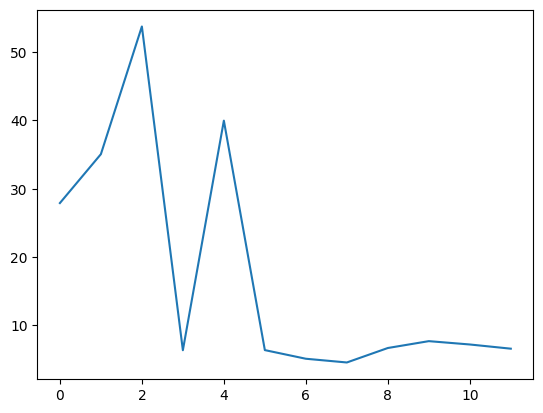

In [23]:
# draw matplotlib
import matplotlib.pyplot as plt
losses = np.loadtxt('losses/training_losses.txt')
plt.plot(losses)
plt.show()


### test SFT model

In [24]:

inp = "who are you  "
response = infer(inp, model)
print("Bot:", response)

Input device: cpu
Model device: cpu


/home/ying/.local/lib/python3.8/site-packages/transformers/generation/configuration_utils.py:615: UserWarning: `num_beams` is set to 1. However, `early_stopping` is set to `True` -- this flag is only used in beam-based generation modes. You should set `num_beams>1` or unset `early_stopping`.
  warnings.warn(


Raw output: tensor([[50258,   508,   389,   345,   220,   220,   220, 50260,   220, 50257,
         50257, 50258, 50257, 50260, 50257,   220, 50258, 50260, 50260, 50258,
         50259]])
Bot:  who are you    <bot>:   <bot>:   <bot>: <bot>:


### load SFT model and test

In [25]:
# Load model and resize token embeddings
model_finetuned = GPT2LMHeadModel.from_pretrained("gpt2")
model_finetuned.resize_token_embeddings(len(tokenizer))

# Load the saved state
model_finetuned.load_state_dict(torch.load("model_state.pt"))
model_finetuned = model_finetuned.to(device)
model_finetuned.eval()  # Set to evaluation mode


/tmp/ipykernel_3518927/1747311727.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model_finetuned.load_state_dict(torch.load("model_state.pt"))


GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50261, 768)
    (wpe): Embedding(1024, 768)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-11): 12 x GPT2Block(
        (ln_1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2SdpaAttention(
          (c_attn): Conv1D()
          (c_proj): Conv1D()
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D()
          (c_proj): Conv1D()
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=768, out_features=50261, bias=False)
)

In [26]:
inp = "who are you  "
response = infer(inp, model_finetuned)
print("Bot:", response)

Input device: cpu
Model device: cpu
Raw output: tensor([[50258,   508,   389,   345,   220,   220,   220, 50260,   220, 50257,
         50257, 50260, 50257, 50258, 50257,   393, 50257,   284, 50257,   220,
         50259]])
Bot:  who are you    <bot>:   <bot>:  or to 
